In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
import os
import IPython.display as display
import sys

# Cau hinh cac tham so chuan cho bai thu nghiem
LOWE_RATIO_THRESH = 0.6
RANSAC_REPROJ_THRESH = 5.0

print("Libraries and const imported.")

Libraries and const imported.


In [12]:
# input image alorithm: SIFT, ORB, AKAZE
# output keypoints kp, descriptors des
def extract_features(image, algorithm='SIFT'):
    """
    Extract keypoints and descriptors from an image using SIFT, ORB, or AKAZE.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    if algorithm.upper() == 'SIFT':
        detector = cv2.SIFT_create()
    elif algorithm.upper() == 'ORB':
        detector = cv2.ORB_create(nfeatures=5000)
    elif algorithm.upper() == 'AKAZE':
        detector = cv2.AKAZE_create()
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    kp, des = detector.detectAndCompute(gray, None)
    return kp, des

def visualize_keypoints(images, keypoints_list, titles=None):
    """
    Visualize detected keypoints on multiple images.
    """
    n = len(images)

    if titles is None:
        titles = [f"Image {i + 1}" for i in range(n)]

    fig, axes = plt.subplots(1, n, figsize=(7 * n, 6))
    axes = np.atleast_1d(axes)

    for i, (image, keypoints) in enumerate(zip(images, keypoints_list)):
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        vis = cv2.drawKeypoints(
            gray,
            keypoints,
            None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
            color=(255, 0, 0)
        )

        vis = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
        axes[i].imshow(vis)
        axes[i].set_title(f"{titles[i]}\n{len(keypoints)} keypoints")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# input set of descriptors from two images, output list of good matches 
# ratio_thresh: threshold for Lowe's ratio test
# L2, HAMMING
# output good matches
def match_features(des1, des2, algorithm='SIFT', ratio_thresh=0.7):
    """
    Match descriptors from two images using appropriate distance metric and matcher.
    """
    if des1 is None or des2 is None or len(des1) == 0 or len(des2) == 0:
        return []

    if algorithm.upper() in ['SIFT', 'AKAZE']:
        # L2 norm for SIFT/AKAZE descriptors
        matcher = cv2.BFMatcher(cv2.NORM_L2)
    elif algorithm.upper() == 'ORB':
        # Hamming distance for binary ORB descriptors
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    raw_matches = matcher.knnMatch(des1, des2, k=2)

    # Apply Lowe's ratio test
    good_matches = []
    for m, n in raw_matches:
        if m.distance < ratio_thresh * n.distance:
            good_matches.append(m)

    return good_matches

# input keypoints from two images and list of matches, 
# output homography matrix (H), mask of inliers, and inlier ratio
# meaning?
def estimate_homography(kp1, kp2, matches, reproj_thresh=5.0):
    """
    Estimate Homography matrix using RANSAC and keep track of inliers and metrics.
    """
    if len(matches) < 4:
        return None, None, 0.0

    src_pts = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, reproj_thresh)

    inliers_count = int(np.sum(mask)) if mask is not None else 0
    inlier_ratio = inliers_count / len(matches) if len(matches) > 0 else 0.0

    return H, mask, inlier_ratio

# input three images and two homography matrices, 
# output stitched image
def stitch_three_images(img1, img2, img3, H12, H32):
    """
    Stitch three images aligned to the coordinate frame of the middle image (img2).
    H12: Homography mapping img1 to img2 (dst: img2, src: img1)
    H32: Homography mapping img3 to img2 (dst: img2, src: img3)
    """
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    h3, w3 = img3.shape[:2]

    # Corners of each image
    corners1 = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)
    corners2 = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    corners3 = np.float32([[0, 0], [0, h3], [w3, h3], [w3, 0]]).reshape(-1, 1, 2)

    # Transform corners to the central frame (img2)
    warped_corners1 = cv2.perspectiveTransform(corners1, H12) if H12 is not None else corners1
    warped_corners3 = cv2.perspectiveTransform(corners3, H32) if H32 is not None else corners3

    all_corners = np.concatenate((corners2, warped_corners1, warped_corners3), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    tx = -x_min if x_min < 0 else 0
    ty = -y_min if y_min < 0 else 0

    T = np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=np.float32)

    output_w = x_max - x_min
    output_h = y_max - y_min

    # Warp all images to the common canvas
    canvas_img2 = cv2.warpPerspective(img2, T, (output_w, output_h))

    H12_translated = T.dot(H12) if H12 is not None else T
    canvas_img1 = cv2.warpPerspective(img1, H12_translated, (output_w, output_h))

    H32_translated = T.dot(H32) if H32 is not None else T
    canvas_img3 = cv2.warpPerspective(img3, H32_translated, (output_w, output_h))

    # Composite the images together (basic blending/overlay)
    # Mask regions
    mask1 = (cv2.cvtColor(canvas_img1, cv2.COLOR_BGR2GRAY) > 0)
    mask2 = (cv2.cvtColor(canvas_img2, cv2.COLOR_BGR2GRAY) > 0)
    mask3 = (cv2.cvtColor(canvas_img3, cv2.COLOR_BGR2GRAY) > 0)

    output = np.zeros_like(canvas_img2)
    output[mask3] = canvas_img3[mask3]
    output[mask1] = canvas_img1[mask1]
    output[mask2] = canvas_img2[mask2]  # Keep center image details on top where they overlap

    return output

def stitch_two_images(img1, img2, H12):
    # # Lấy kích thước ảnh đầu vào
    # h1, w1 = img1.shape[:2]
    # h2, w2 = img2.shape[:2]

    # # Tính toán kích thước cho ảnh Panorama đầu ra
    # # (Thông thường ảnh kết quả sẽ có chiều rộng lớn hơn tổng thể để chứa phần ghép)
    # width_output = w1 + w2
    # height_output = max(h1, h2)

    # # Thực hiện biến đổi phối cảnh trên ảnh 2 bằng ma trận H
    # result = cv2.warpPerspective(img2, H12, (width_output, height_output))

    # # Đè ảnh 1 lên vùng không gian tương ứng của ảnh kết quả
    # result[0:h1, 0:w1] = img1

    # # Cắt bỏ bớt khoảng đen dư thừa ở bên phải nếu có
    # gray_result = cv2.cvtColor(result, cv2.COLOR_BGR2GRAY)
    # _, thresh = cv2.threshold(gray_result, 1, 255, cv2.THRESH_BINARY)
    # contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # x, y, w, h = cv2.boundingRect(contours[0])
    # cropped_result = result[y:y+h, x:x+w]

    # return cropped_result

    """
    Stitch two images aligned to the coordinate frame of the second image (img2).
    H12: Homography mapping img1 to img2 (dst: img2, src: img1)
    """
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    # Corners of each image
    corners1 = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)
    corners2 = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)

    # Transform corners to the central frame (img2)
    warped_corners1 = cv2.perspectiveTransform(corners1, H12) if H12 is not None else corners1

    all_corners = np.concatenate((corners2, warped_corners1), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    tx = -x_min if x_min < 0 else 0
    ty = -y_min if y_min < 0 else 0

    T = np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=np.float32)

    output_w = x_max - x_min
    output_h = y_max - y_min

    # Warp all images to the common canvas
    canvas_img2 = cv2.warpPerspective(img2, T, (output_w, output_h))

    H12_translated = T.dot(H12) if H12 is not None else T
    canvas_img1 = cv2.warpPerspective(img1, H12_translated, (output_w, output_h))

    # Composite the images together (basic blending/overlay)
    # Mask regions
    mask1 = (cv2.cvtColor(canvas_img1, cv2.COLOR_BGR2GRAY) > 0)
    mask2 = (cv2.cvtColor(canvas_img2, cv2.COLOR_BGR2GRAY) > 0)

    output = np.zeros_like(canvas_img2)
    output[mask1] = canvas_img1[mask1]
    output[mask2] = canvas_img2[mask2]  # Keep center image details on top where they overlap

    return output

def images_stitching(img1, img2, algo='SIFT', img3=None, show_origin=False, show_keypoints=False, show_matches=False, show_panorama=True):    
    # Hien thi các ảnh
    isThree = img3 is not None

    if show_origin:
        fig, axes = plt.subplots(1, 3 if isThree else 2, figsize=(12, 6))
        axes[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
        axes[0].set_title("Ảnh 1")
        axes[0].axis('off')

        axes[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
        axes[1].set_title("Ảnh 2")
        axes[1].axis('off')

        if isThree:
            axes[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
            axes[2].set_title("Ảnh 3")
            axes[2].axis('off')

        plt.tight_layout()
        plt.show()

    print(f"\n{'='*25} {algo} {'='*25}")
    start_time = time.time()

    # 1. Feature Extraction
    kp1, des1 = extract_features(img1, algorithm=algo)
    kp2, des2 = extract_features(img2, algorithm=algo)
    if isThree:
        kp3, des3 = extract_features(img3, algorithm=algo)

    if show_keypoints:
        visualize_keypoints(
            [img1, img2, img3] if isThree else [img1, img2],
            [kp1, kp2, kp3] if isThree else [kp1, kp2],
            titles=['Image 1', 'Image 2', 'Image 3'] if isThree else ['Image 1', 'Image 2']
        )
    
    # 2. Feature Matching
    matches12 = match_features(
        des1, des2, algorithm=algo,
        ratio_thresh=LOWE_RATIO_THRESH
    )
    if isThree:
        matches32 = match_features(
            des3, des2, algorithm=algo,
            ratio_thresh=LOWE_RATIO_THRESH
        )

    if show_matches:
        img_matches = cv2.drawMatches(img1, kp1, img2, kp2, matches12[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        plt.figure(figsize=(20, 10))
        plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
        plt.title("Các cặp điểm khớp đặc trưng tiêu biểu")
        plt.axis('off')
        plt.show()

        if isThree:
            img_matches = cv2.drawMatches(img3, kp3, img2, kp2, matches32[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
            plt.figure(figsize=(20, 10))
            plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
            plt.title("Các cặp điểm khớp đặc trưng tiêu biểu")
            plt.axis('off')
            plt.show()

    # 3. Homography Estimation
    H12, mask12, inlier_ratio12 = estimate_homography(
        kp1, kp2, matches12,
        reproj_thresh=RANSAC_REPROJ_THRESH
    )
    if isThree:
        H32, mask32, inlier_ratio32 = estimate_homography(
            kp3, kp2, matches32,
            reproj_thresh=RANSAC_REPROJ_THRESH
        )

    elapsed_time = time.time() - start_time

    inliers12 = int(np.sum(mask12)) if mask12 is not None else 0
    if isThree:
        inliers32 = int(np.sum(mask32)) if mask32 is not None else 0

    # 4. Display metrics immediately
    metrics = {
        'Metric': [
            'Keypoints',
            'Good Matches (1->2)',
            'Good Matches (3->2)',
            'RANSAC Inliers (1->2)',
            'RANSAC Inliers (3->2)',
            'Inlier Ratio (1->2)',
            'Inlier Ratio (3->2)',
            'Execution Time (s)'
        ],
        'Value': [
            [len(kp1), len(kp2), len(kp3)],
            len(matches12),
            len(matches32),
            inliers12,
            inliers32,
            f"{inlier_ratio12 * 100:.2f}%",
            f"{inlier_ratio32 * 100:.2f}%",
            round(elapsed_time, 4)
        ]
    } if isThree else {
        'Metric': [
            'Keypoints',
            'Good Matches (1->2)',
            'RANSAC Inliers (1->2)',
            'Inlier Ratio (1->2)',
            'Execution Time (s)'
        ],
        'Value': [
            [len(kp1), len(kp2)],
            len(matches12),
            inliers12,
            f"{inlier_ratio12 * 100:.2f}%",
            round(elapsed_time, 4)
        ]
    }

    # 5. Stitch and display panorama
    if isThree:
        panorama = stitch_three_images(img1, img2, img3, H12, H32)
    else:
        panorama = stitch_two_images(img1, img2, H12)

    if show_panorama:
        plt.figure(figsize=(16, 6))
        plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
        plt.title(f"Panorama generated by {algo}")
        plt.axis('off')
        plt.show()

    return metrics

print("Helper functions successfully defined.")


Helper functions successfully defined.


Nạp ảnh (init)

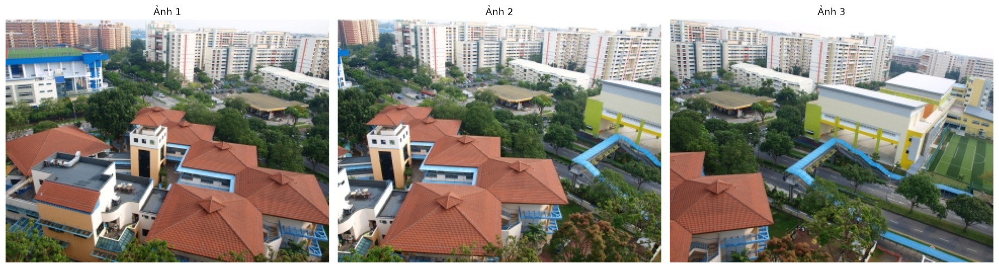

In [13]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
img1_path = 'input/sample_01.jpg'
img2_path = 'input/sample_02.jpg'
img3_path = 'input/sample_03.jpg'

if 'img1' not in globals() and os.path.exists(img1_path):
    img1 = cv2.imread(img1_path)
if 'img2' not in globals() and os.path.exists(img2_path):
    img2 = cv2.imread(img2_path)
if 'img3' not in globals() and os.path.exists(img3_path):
    img3 = cv2.imread(img3_path)

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
axes[2].set_title("Ảnh 3")
axes[2].axis('off')

plt.tight_layout()
plt.show()

Benchmark


========================= SIFT =========================


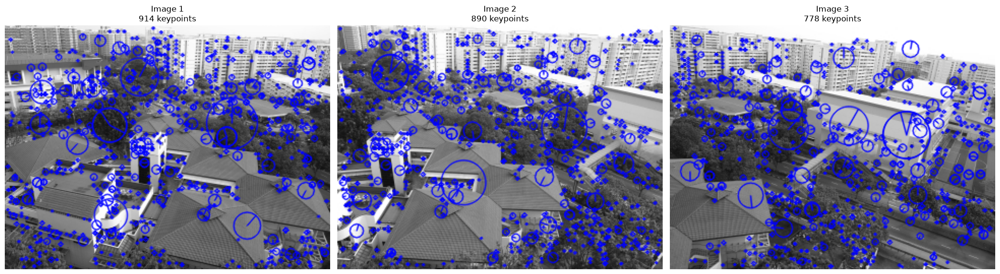

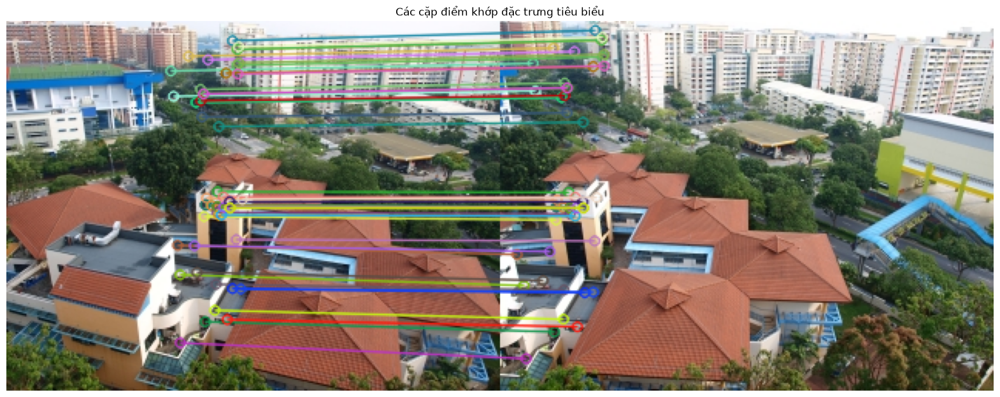

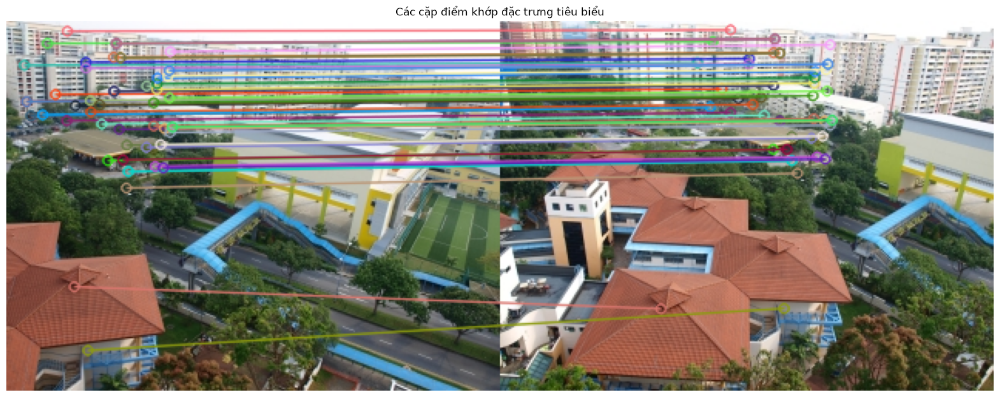

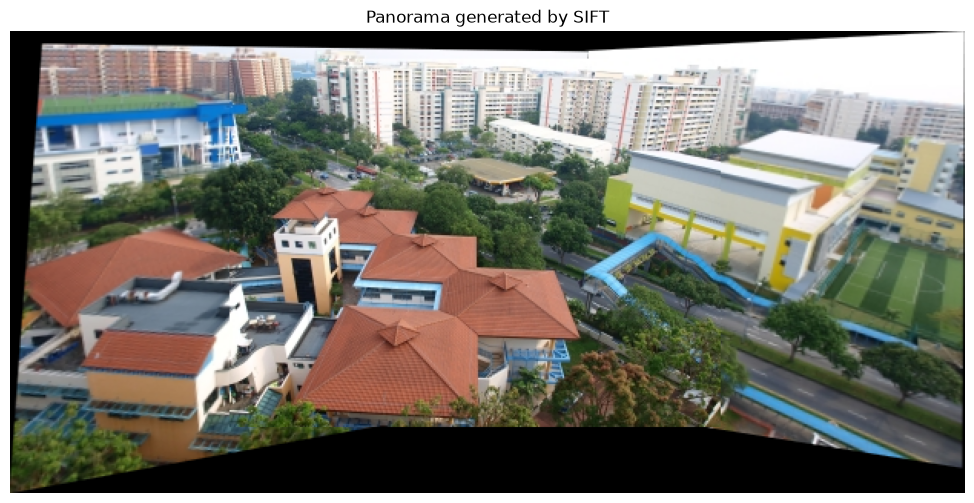


========================= ORB =========================


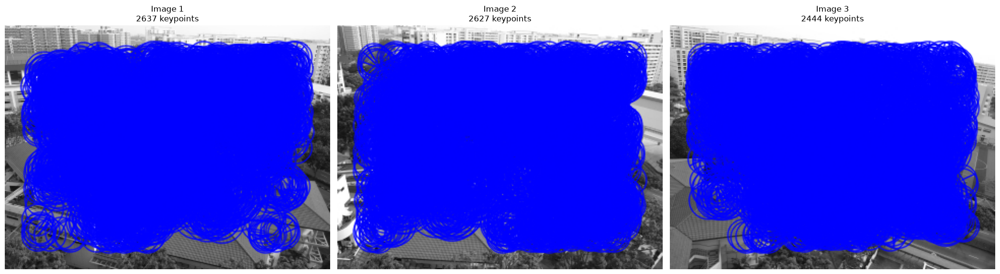

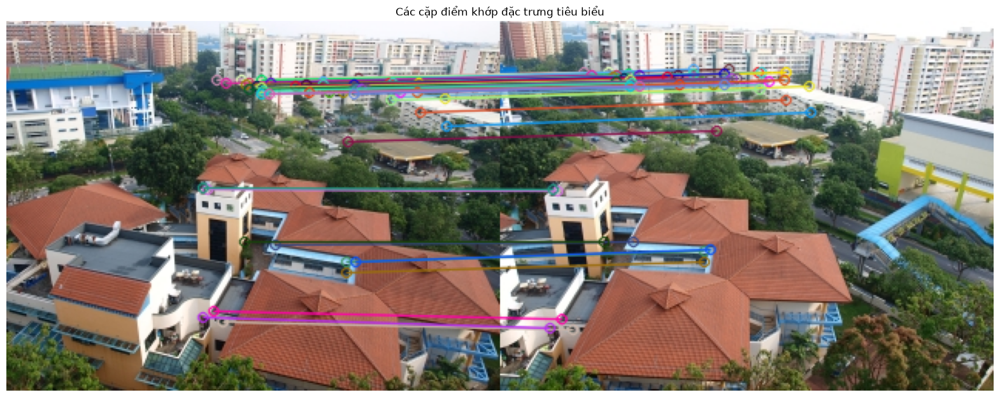

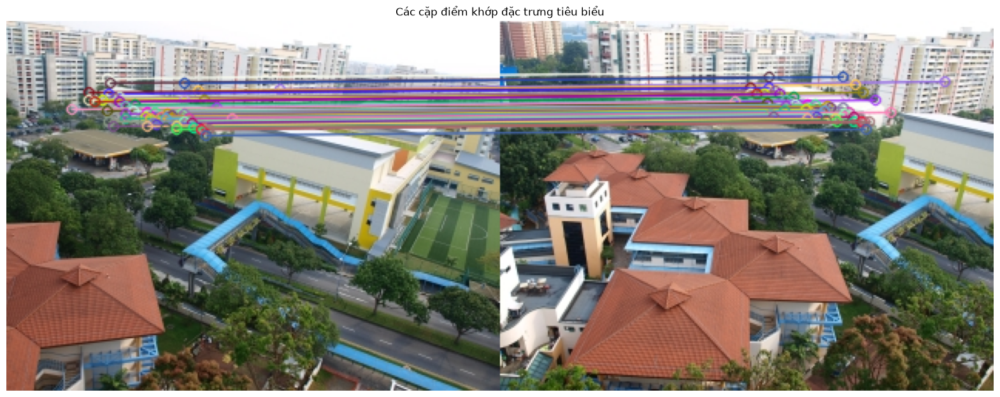

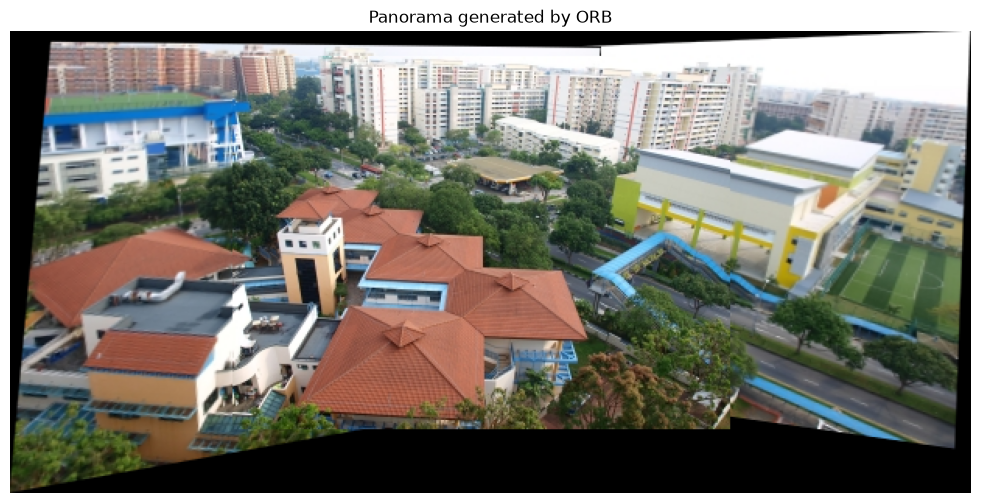


========================= AKAZE =========================


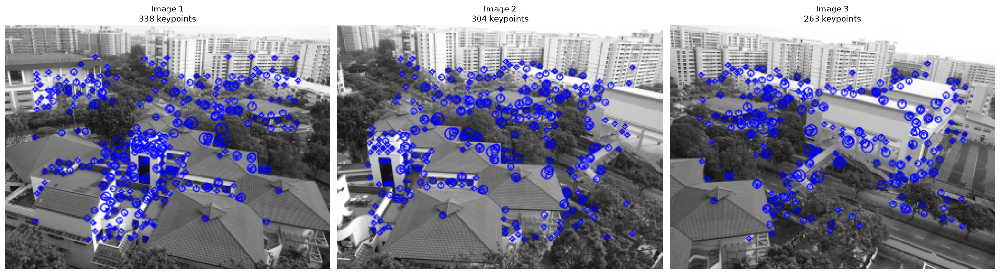

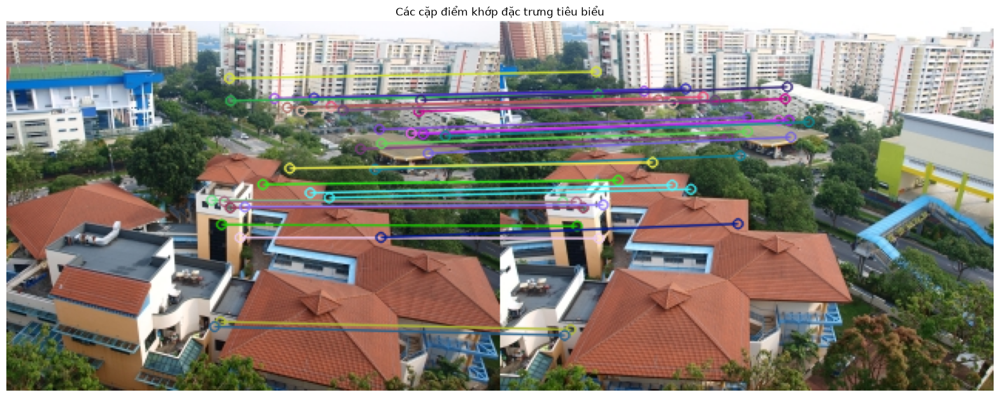

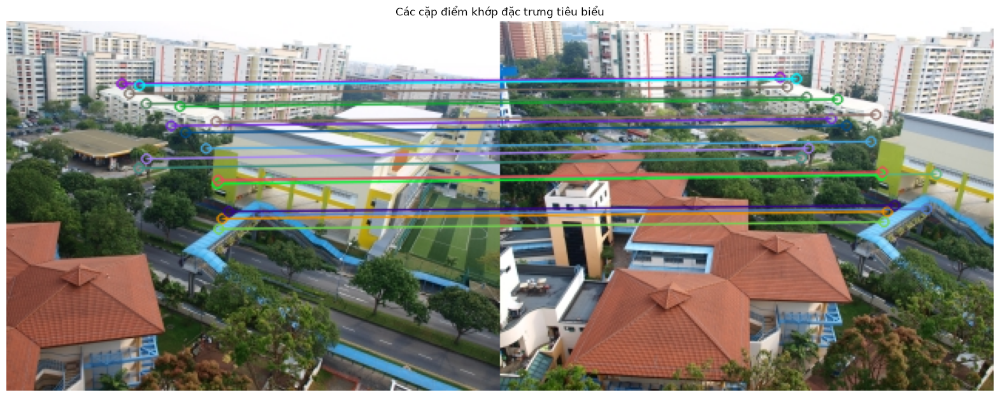

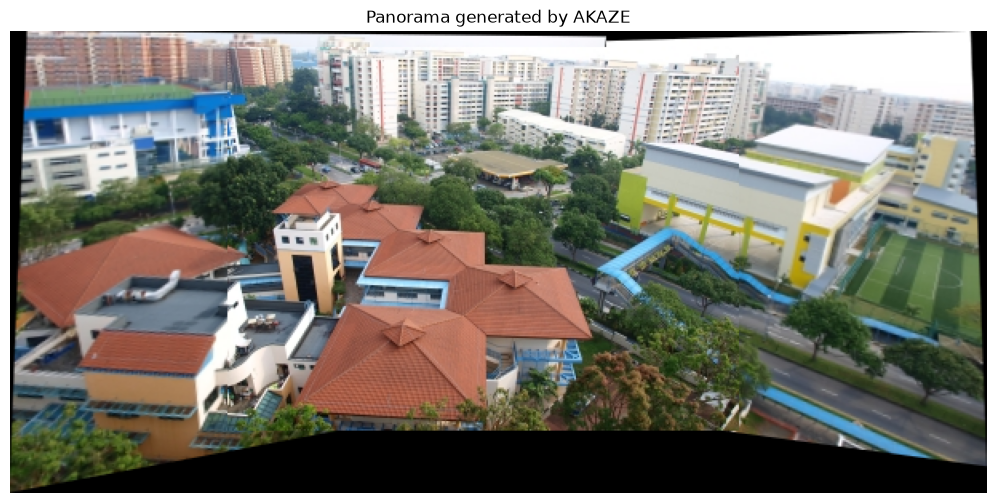

Metric,Keypoints,Good Matches (1->2),Good Matches (3->2),RANSAC Inliers (1->2),RANSAC Inliers (3->2),Inlier Ratio (1->2),Inlier Ratio (3->2),Execution Time (s)
Algorithm,,,,,,,,
SIFT,"[914, 890, 778]",170,91,166,83,97.65%,91.21%,2.0446
ORB,"[2637, 2627, 2444]",248,138,247,138,99.60%,100.00%,1.9138
AKAZE,"[338, 304, 263]",32,18,32,18,100.00%,100.00%,1.7285


In [14]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics = images_stitching(
        img1, img2, img3=img3,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)

# Robustness test
## Low-light picture

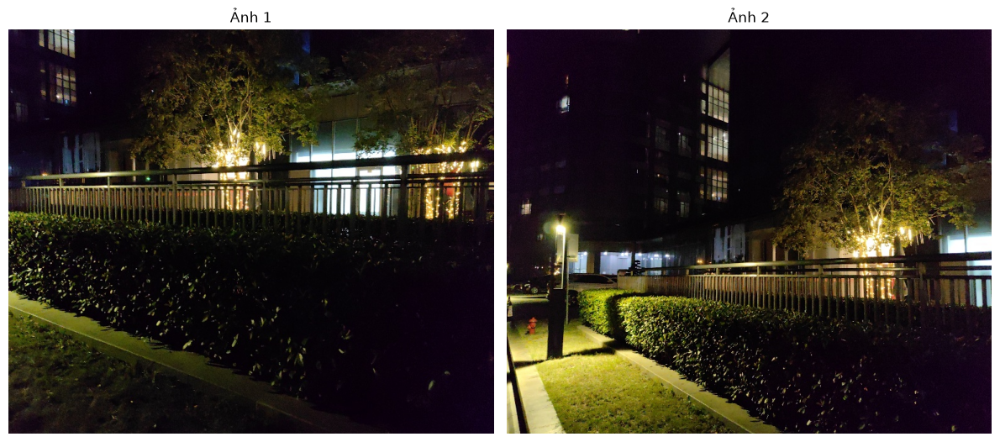

In [15]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
lowlight1_path = 'input/robust_lowlight_01.jpg'
lowlight2_path = 'input/robust_lowlight_02.jpg'

if 'lowlight1' not in globals() and os.path.exists(lowlight1_path):
    lowlight1 = cv2.imread(lowlight1_path)
if 'lowlight2' not in globals() and os.path.exists(lowlight2_path):
    lowlight2 = cv2.imread(lowlight2_path)

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(lowlight1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(lowlight2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

plt.tight_layout()
plt.show()


========================= SIFT =========================


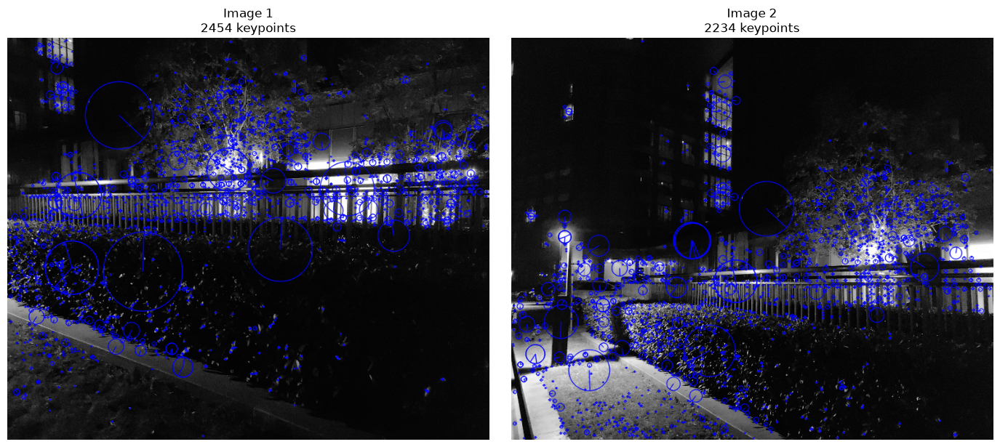

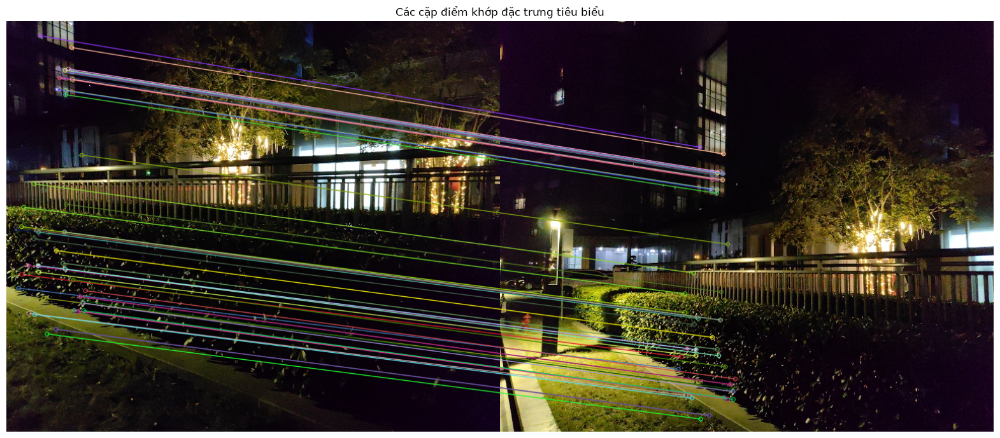

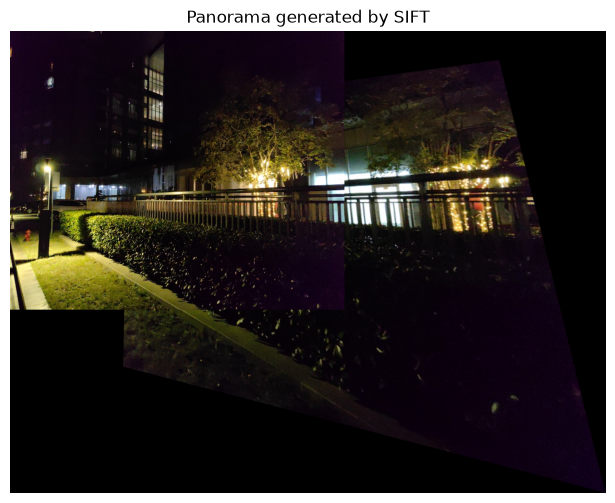


========================= ORB =========================


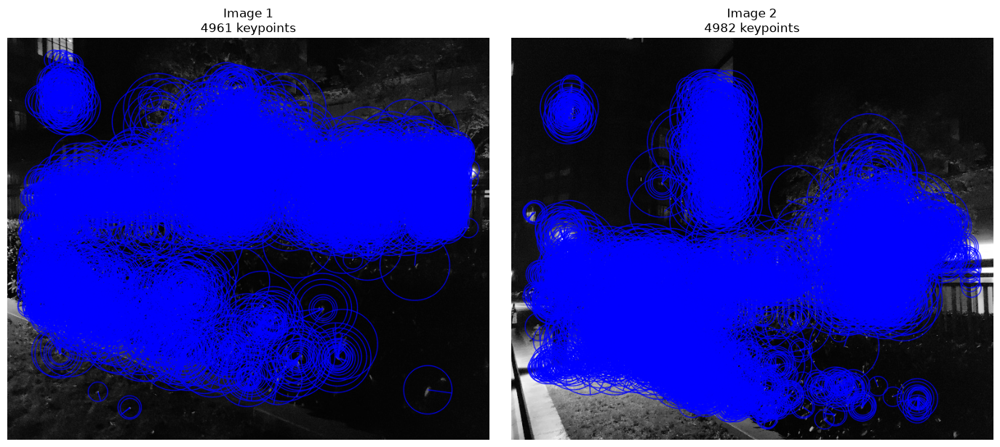

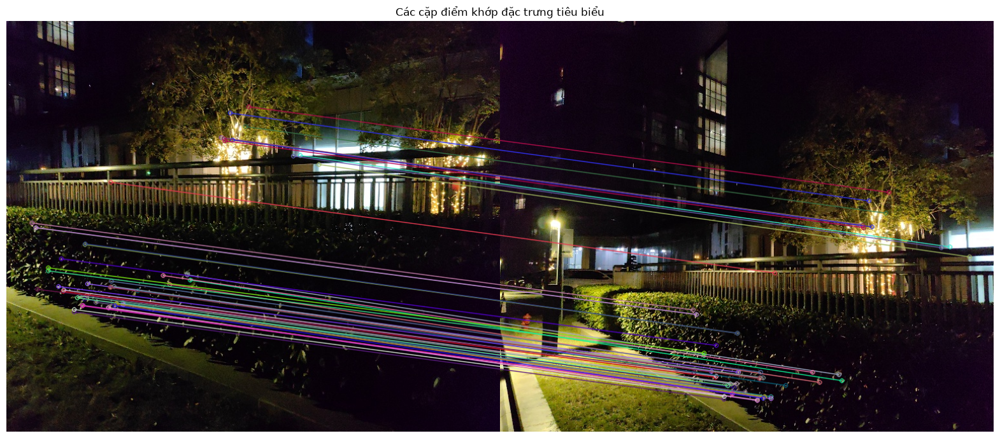

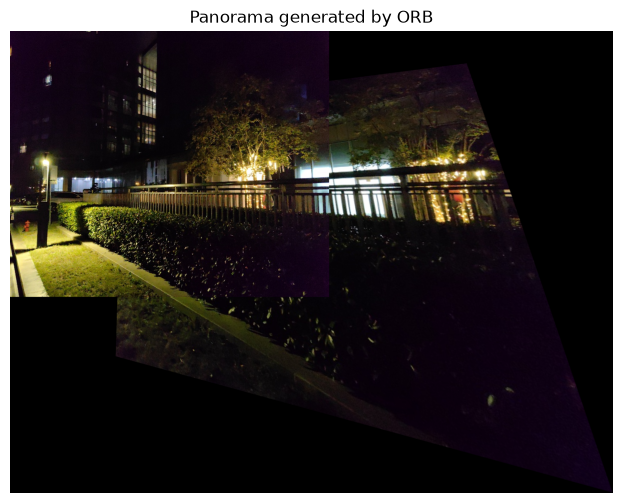


========================= AKAZE =========================


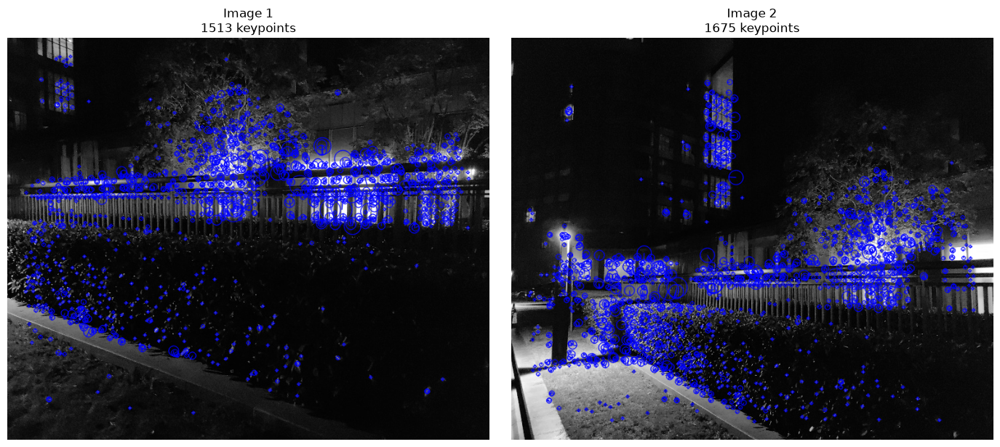

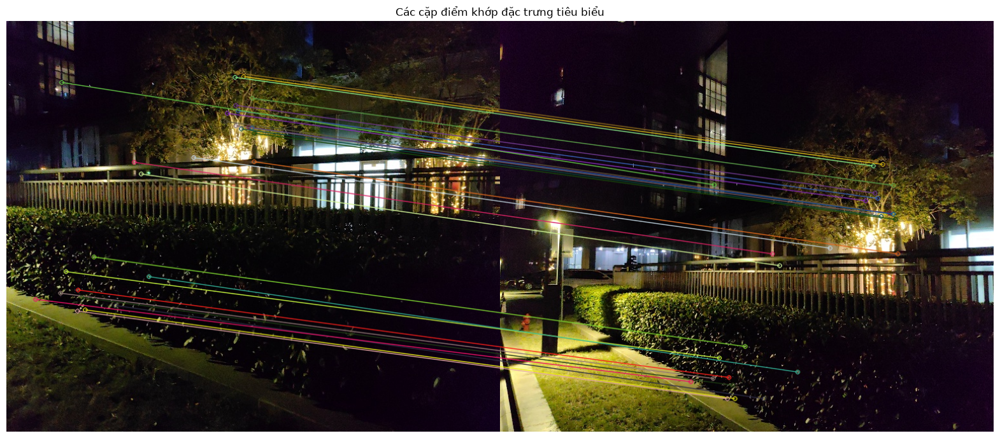

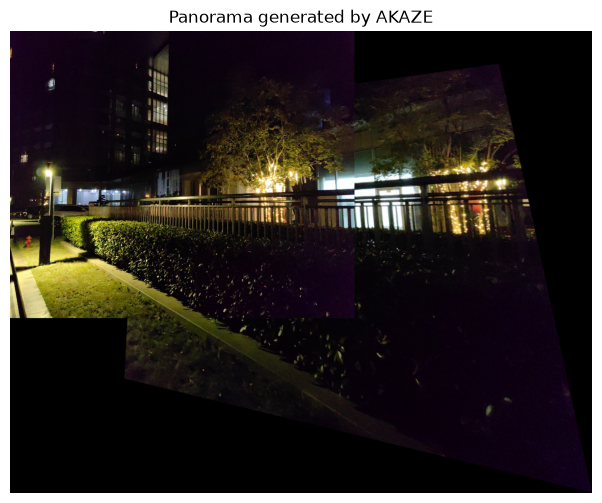

Metric,Keypoints,Good Matches (1->2),RANSAC Inliers (1->2),Inlier Ratio (1->2),Execution Time (s)
Algorithm,,,,,
SIFT,"[2454, 2234]",117,101,86.32%,1.5622
ORB,"[4961, 4982]",121,99,81.82%,1.5667
AKAZE,"[1513, 1675]",28,21,75.00%,1.4189


In [16]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics = images_stitching(
        lowlight1, lowlight2,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)

## Illumination/ Color Inconsistent

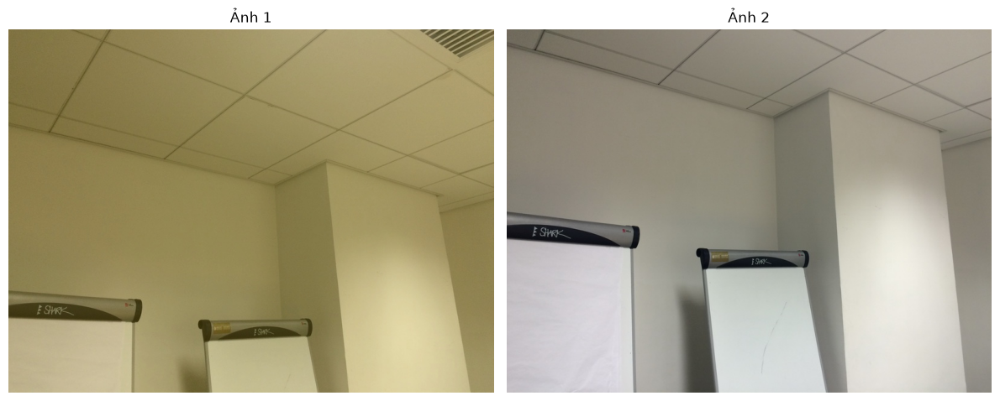

In [17]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
illumination1_path = 'input/robust_illumination_01.jpg'
illumination2_path = 'input/robust_illumination_02.jpg'

if 'illumination1' not in globals() and os.path.exists(illumination1_path):
    illumination1 = cv2.imread(illumination1_path)
if 'illumination2' not in globals() and os.path.exists(illumination2_path):
    illumination2 = cv2.imread(illumination2_path)

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(illumination1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(illumination2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

plt.tight_layout()
plt.show()



========================= SIFT =========================


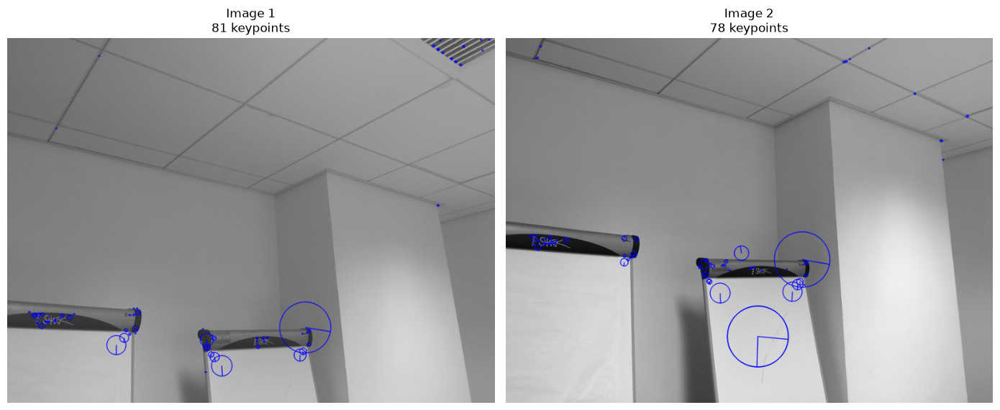

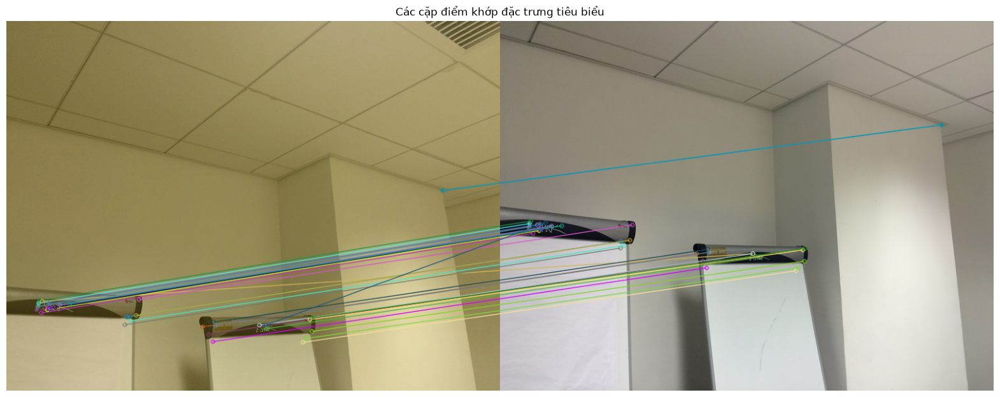

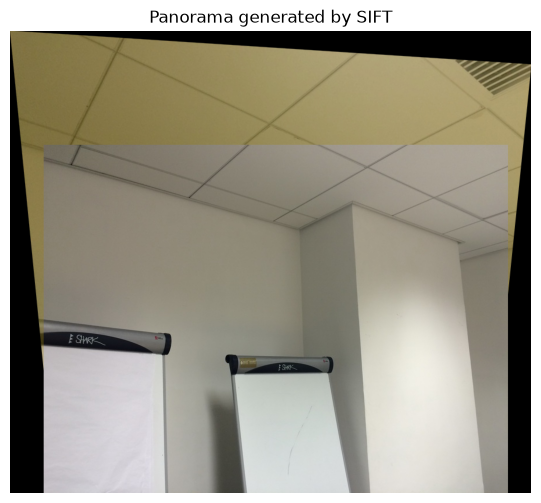


========================= ORB =========================


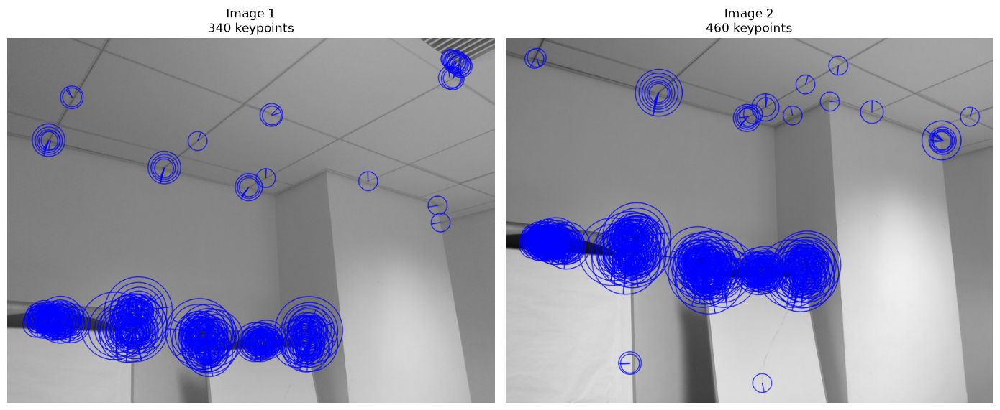

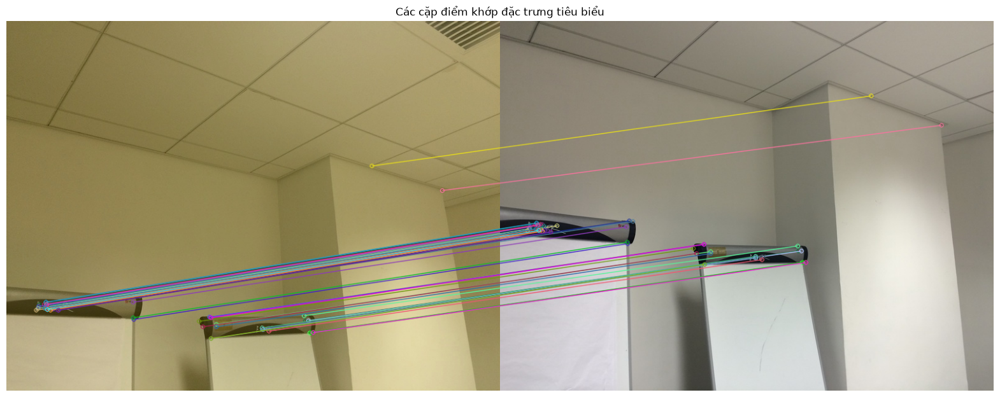

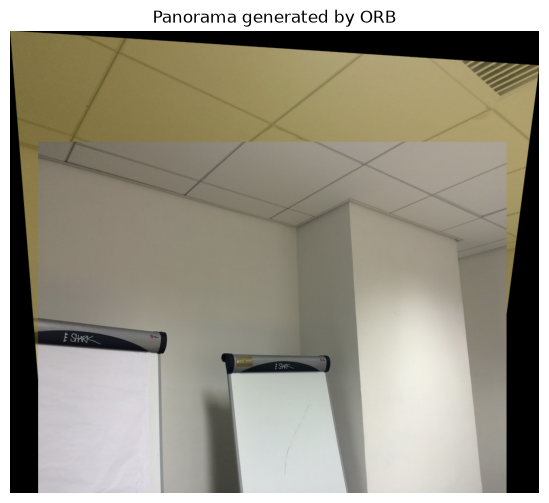


========================= AKAZE =========================


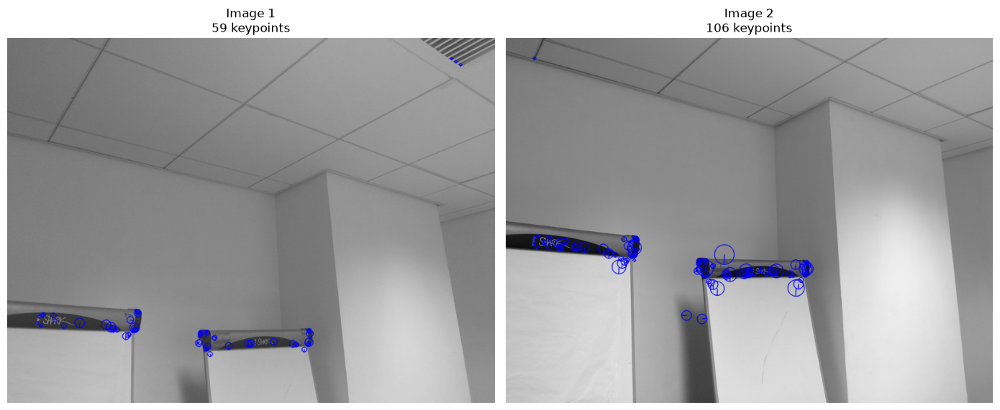

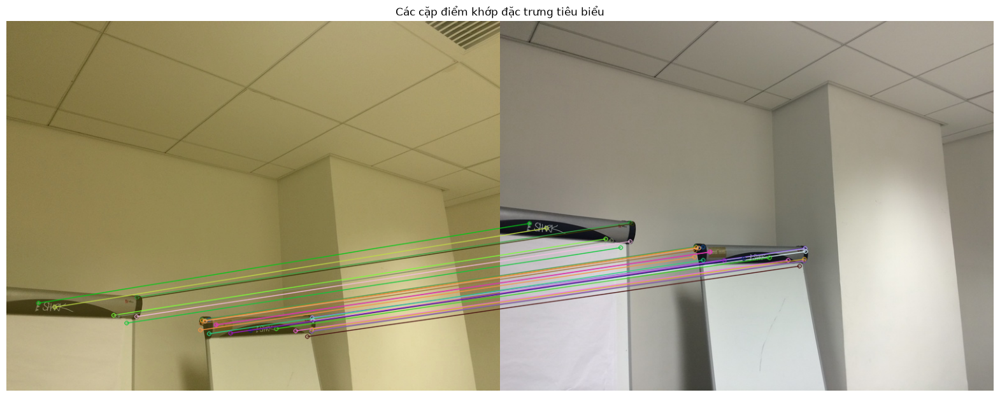

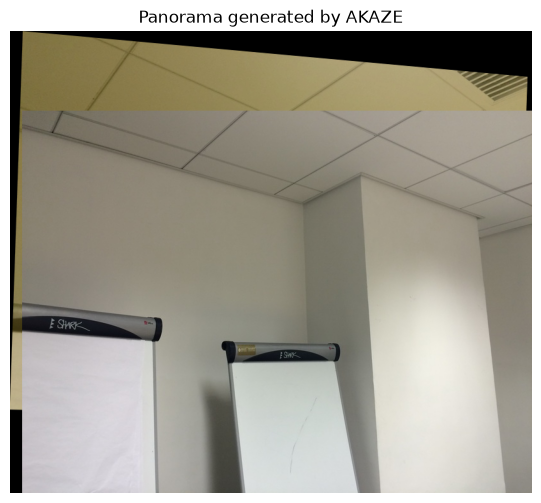

Metric,Keypoints,Good Matches (1->2),RANSAC Inliers (1->2),Inlier Ratio (1->2),Execution Time (s)
Algorithm,,,,,
SIFT,"[81, 78]",35,33,94.29%,1.3128
ORB,"[340, 460]",84,82,97.62%,1.0641
AKAZE,"[59, 106]",28,26,92.86%,1.3013


In [18]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics = images_stitching(
        illumination1, illumination2,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)

## Large homography (large different perspective)

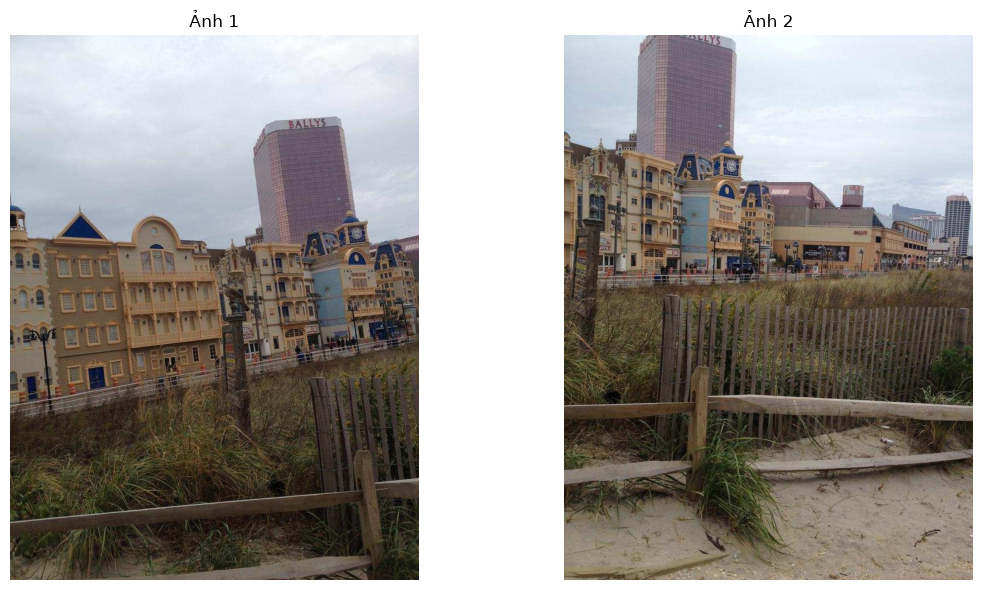

In [19]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
perspective1_path = 'input/robust_perspective_01.jpg'
perspective2_path = 'input/robust_perspective_02.jpg'

if 'perspective1' not in globals() and os.path.exists(perspective1_path):
    perspective1 = cv2.imread(perspective1_path)
if 'perspective2' not in globals() and os.path.exists(perspective2_path):
    perspective2 = cv2.imread(perspective2_path)

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(perspective1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(perspective2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

plt.tight_layout()
plt.show()


========================= SIFT =========================


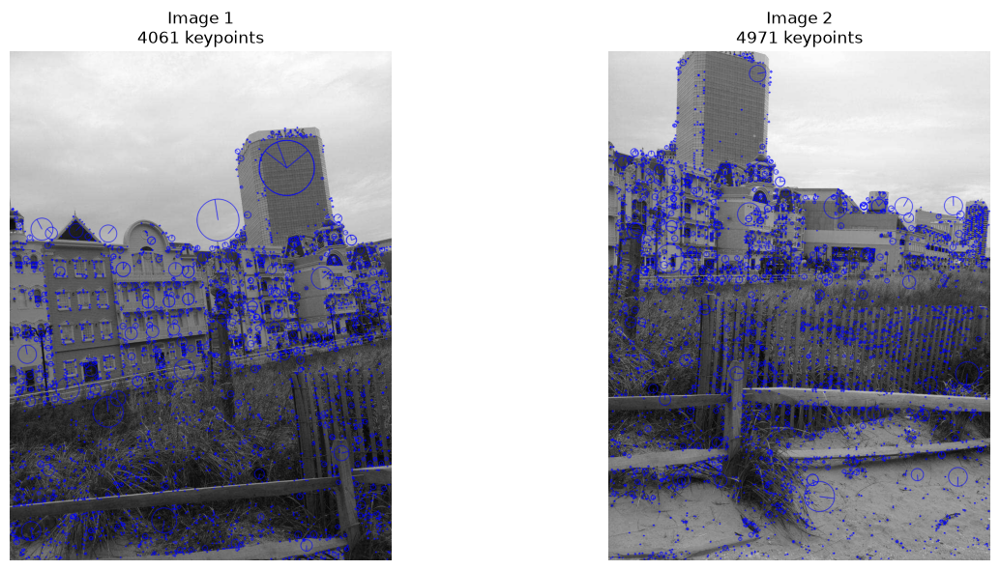

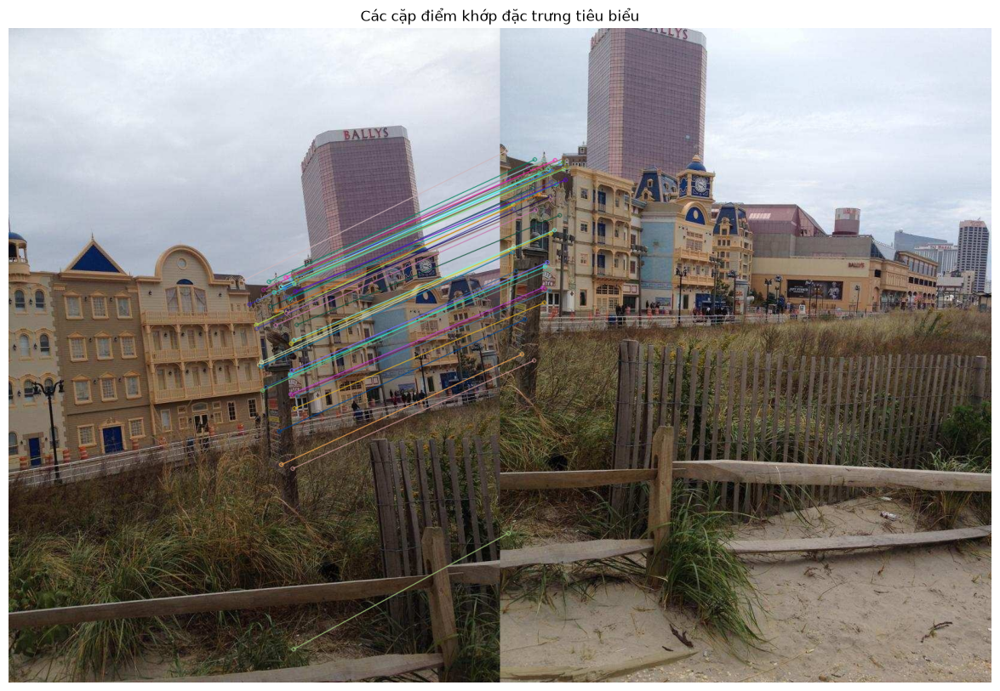

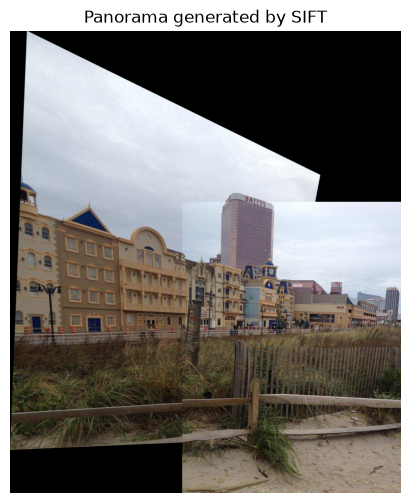


========================= ORB =========================


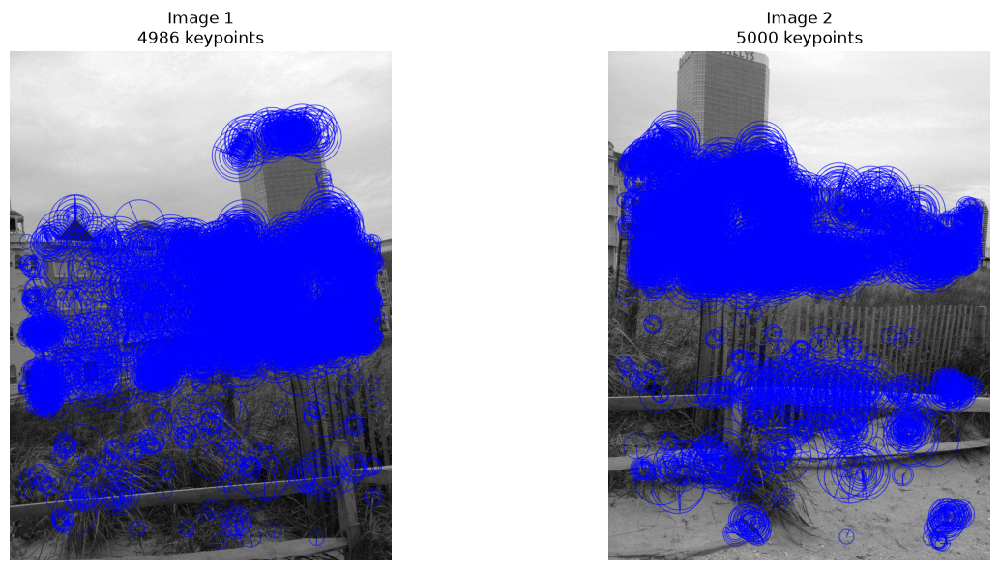

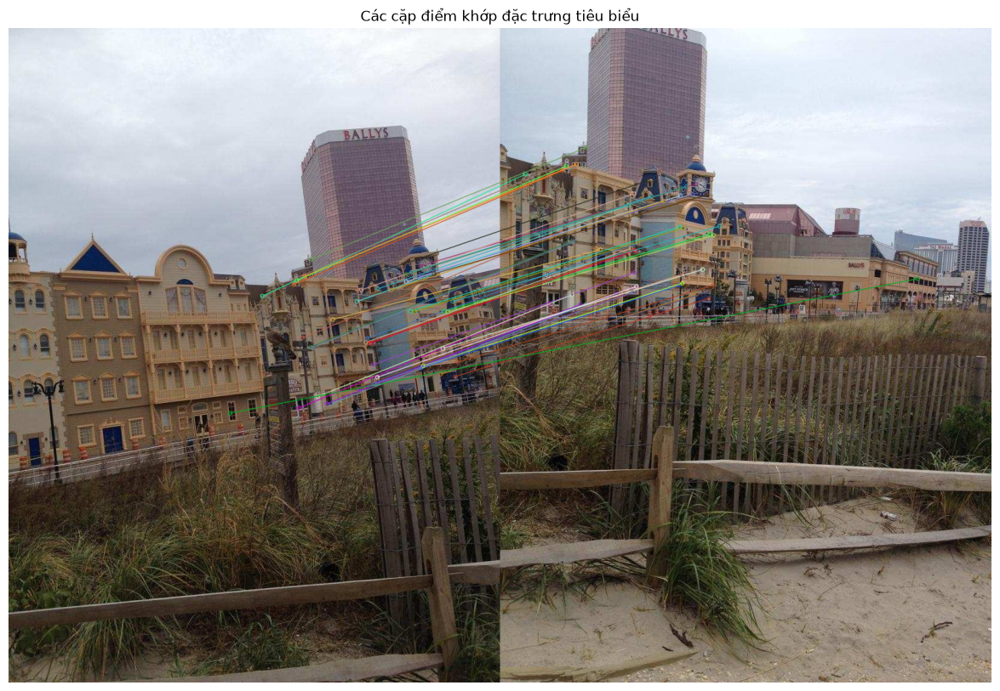

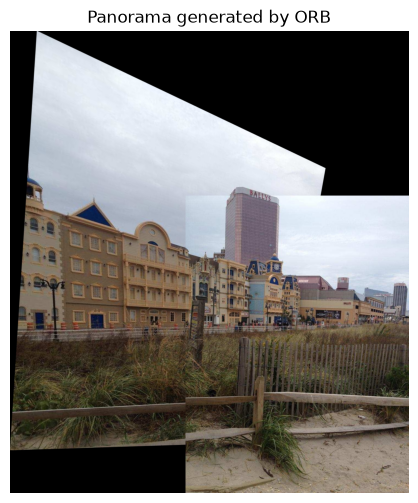


========================= AKAZE =========================


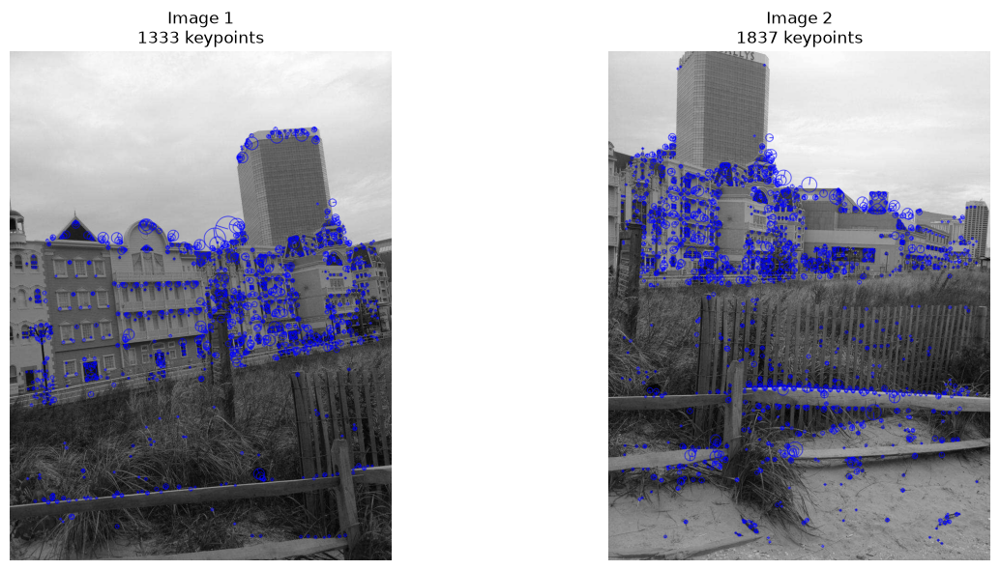

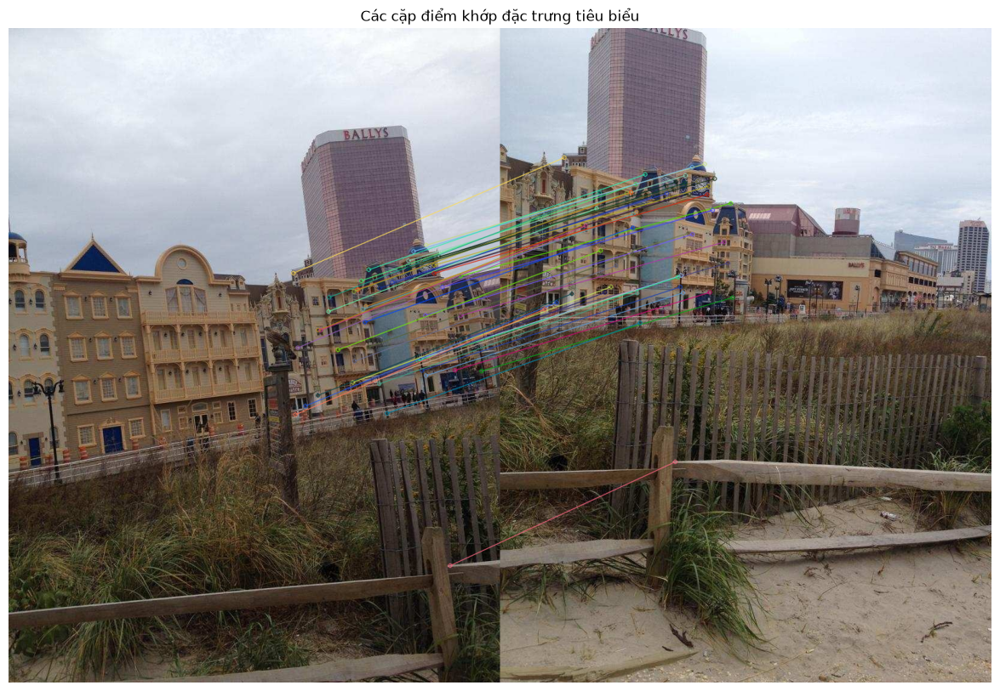

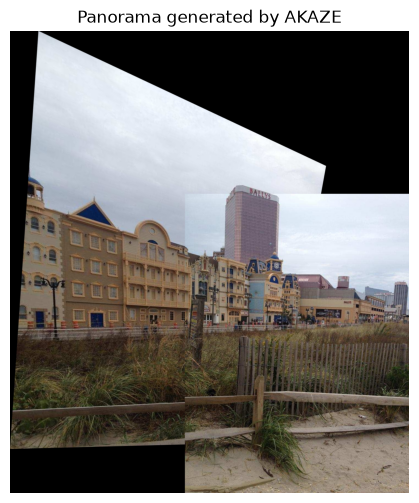

Metric,Keypoints,Good Matches (1->2),RANSAC Inliers (1->2),Inlier Ratio (1->2),Execution Time (s)
Algorithm,,,,,
SIFT,"[4061, 4971]",454,407,89.65%,2.0036
ORB,"[4986, 5000]",518,508,98.07%,1.6194
AKAZE,"[1333, 1837]",154,148,96.10%,1.6822


In [20]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics = images_stitching(
        perspective1, perspective2,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)